lane_count nicht vorhanden -> Daten werden nicht gefiltert.
Bildhöhe: 240
Bildbreite: 320
Bilddimension: 3


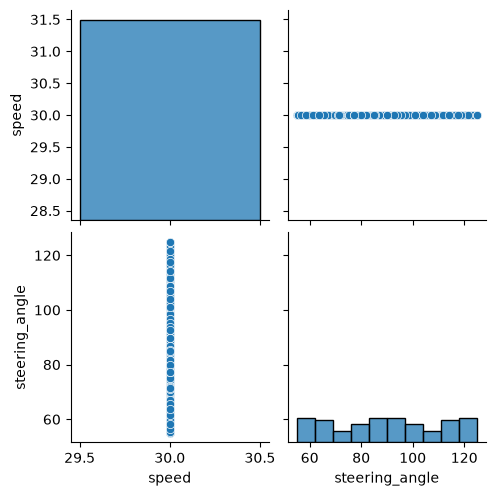

In [ ]:
from pathlib import Path
 
import pandas as pd
import numpy as np
import warnings
 
import seaborn as sns
 
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import tensorflow as tf
 
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Rescaling, Conv2D, Flatten, Dropout, Dense
 
def import_data(data_path=Path('Data_AI'),
                sub_folder_list=['2026-10-26_14-03-39'],
                lane_filter=True):

    X = []
    Y = []

    first_fig = True

    for sub_folder_value in sub_folder_list:

        csv_path = data_path / sub_folder_value / 'data.csv'
        data = pd.read_csv(csv_path)

        # Optional: Nur Daten mit 2 erkannten Linien verwenden
        if lane_filter:
            try:
                data = data[data['lane_count'] == 2]
            except KeyError:
                print('lane_count nicht vorhanden -> Daten werden nicht gefiltert.')


        images = []

        image_height = None
        image_width = None
        image_dimension = None

        for image_name in data['image']:

            image_path = data_path / sub_folder_value / image_name

            # Beim ersten Bild Originalgröße bestimmen
            if image_height is None:
                first_image = tf.keras.utils.load_img(image_path)
                first_image = tf.keras.utils.img_to_array(first_image)

                image_height, image_width, image_dimension = first_image.shape

                print('Bildhöhe:', image_height)
                print('Bildbreite:', image_width)
                print('Bilddimension:', image_dimension)

            # Alle Bilder auf diese Größe laden
            image = tf.keras.utils.load_img(
                image_path,
                target_size=(image_height, image_width)
            )

            image = tf.keras.utils.img_to_array(image)

            images.append(image)

        X_arr = np.array(images, dtype=np.float32)
        X_flipped = tf.image.flip_left_right(X_arr)

        Y_arr = data[['speed', 'steering_angle']].to_numpy(dtype=np.float32)

        Y_flipped = Y_arr.copy()
        Y_flipped[:, 1] = 180 - Y_flipped[:, 1]

        X.append(X_arr)
        X.append(X_flipped)

        Y.append(Y_arr)
        Y.append(Y_flipped)

    X = np.concatenate(X, axis=0)
    Y = np.concatenate(Y, axis=0)

    return X, Y, image_height, image_width, image_dimension
 
# Pfad zu den Daten
data_path = Path('Data_AI')
sub_folder = ["2026-10-27_14-03-39"]
 
# Daten einlesen
X, Y, fig_heigt, fig_width, fig_dim = import_data(data_path = data_path,
                                                  sub_folder_list = sub_folder)
 
# DataFrame für Pandas
data = pd.DataFrame(Y,columns=['speed', 'steering_angle'])
# Visualisierung
sns.pairplot(data=data[['speed', 'steering_angle']])
plt.show()


 

Einmal Checken wie die Shepes sind
x: Anzahl der Bilder, Pixel Höhe, Pixel Breite, Anzahl Farbkanäle
y: Anzahl der Werte, Speed, Steeringangle

In [3]:
print('X shape:', X.shape)
print('Y shape:', Y.shape)

print('Erster Output:')
print(Y[0])


X shape: (508, 240, 320, 3)
Y shape: (508, 2)
Erster Output:
[30.     89.2945]


Datensätze mischen:

In [4]:
indices = np.random.permutation(len(X))

X = X[indices]
Y = Y[indices]

Dataset für model aufbauen

In [5]:
dataset = tf.data.Dataset.from_tensor_slices((X, Y))

Dann einmal daten mischen

In [6]:
# Daten mischen
dataset = dataset.shuffle(
    buffer_size=len(X),
    seed=42,
    reshuffle_each_iteration=False
)

Aufteilung in Trainingsdaten, Testdaten und Validierungsdtaen

In [7]:
# Anzahl Daten
n = len(X)

n_train = int(0.70 * n)
n_validate = int(0.15 * n)

# Aufteilen
train_ds = dataset.take(n_train) # Trainingsdaten

remaining_ds = dataset.skip(n_train) # skip -> Alles, was nicht in train_ds steckt, ist nur hier

validate_ds = remaining_ds.take(n_validate) # Validierung - n_validate Daten, die nicht in train_ds ist

test_ds = remaining_ds.skip(n_validate) #  Testdaten -  Alles, was nun noch in remaining_ds steht, aber nicht in validate_ds ist

Compelieren und lernen des Models

- Sequential(...) erzeugt das Netz. Die Gewichte sind zufällig initialisiert, das Modell kann also noch nichts.
- compile() legt fest, dass mit Adam trainiert und der MSE minimiert wird. Der MAE wird nur angezeigt.
- summary() hat die 7.381.314 Parameter ausgegeben.

1. Rescaling(1./255): Damit liegen die Pixelwerte zwischen 0 und 1. Bei kleinen, gleich großen Eingangswerten lernt das Netz stabiler.

2. Conv2D: warum statt Flatten Ein Filter (z. B. 5×5) wird über das ganze Bild geschoben. Er nutzt dabei überall dieselben Gewichte. Daraus folgt zweierlei:

Eine Linie wird erkannt, egal wo sie im Bild liegt.
Die erste Schicht braucht dafür nur 5·5·3·24 + 24 = 1.824 Parameter. Beim alten Modell waren es 7,37 Mio.

3. Warum strides=2 in den ersten drei Schichten: Der Filter springt jeweils 2 Pixel weiter. Dadurch halbiert sich die Bildgröße ungefähr: 120 → 58 → 27 → 12. Formel ohne Padding: out=⌊in−ks⌋+1\text{out} = \left\lfloor \frac{\text{in} - k}{s} \right\rfloor + 1out=⌊sin−k​⌋+1 Das spart Rechenzeit auf dem Raspberry Pi. Außerdem sieht jede tiefere Schicht einen größeren Bildausschnitt.

4. Warum die Kanäle mehr werden (24 → 36 → 48 → 64 → 64): Das Bild wird kleiner, dafür speichert jede Position mehr Merkmale. Vorne gibt es wenige einfache Muster wie Kanten. Hinten gibt es viele zusammengesetzte Muster wie „Linie biegt nach links“.

5. Rezeptives Feld (RF): So groß ist der Bildausschnitt, den ein Merkmal „sieht“. Es wächst von 5 über 13, 29 und 45 auf 61 Pixel. Merkmale am Ende überblicken also ungefähr die halbe Bildhöhe. Das reicht, um Lage und Krümmung einer Spurlinie zu erfassen.

6. Warum am Ende 3×3 statt 5×5: Die Bilder sind dort nur noch 12×17 groß. Ein 5×5-Filter mit Schrittweite 2 würde zu stark verkleinern. Mit 3×3 werden die Merkmale weiter kombiniert, ohne dass zu viel räumliche Information verloren geht.

7. Flatten → 6.656: 8·13·64 = 6.656 Werte. Beim alten Modell waren es 57.600. Gleichzeitig ist jeder Wert jetzt ein Merkmal und kein rohes Pixel.

8. Dropout(0.3): Beim Training wird jedes Mal zufällig 30 % dieser Werte auf null gesetzt. Hier sitzen 665.700 Parameter (83 %), also besteht dort die größte Gefahr, dass das Netz die Trainingsbilder auswendig lernt. Beim Fahren (predict) ist Dropout ausgeschaltet.

9. Dense 100 → 50 → 10: Diese Schichten verdichten die Informationen schrittweise zu einer Entscheidung. Durch die ReLU-Aktivierung kann das Netz auch nichtlineare Zusammenhänge abbilden, z. B. „starke Kurve → überproportional lenken“.

10. Dense(2) ohne Aktivierung: Die Ausgabe sind zwei beliebige Zahlen, speed und steering. Das ist bei einer Regression richtig. Ein relu würde zum Beispiel negative Werte für den Lenkwinkel nach Skalierung abschneiden.



In [8]:
model = Sequential(
    [
        Input(shape=(fig_heigt, fig_width, fig_dim)),
        Rescaling(1./255),
        Conv2D(24, 5, strides=2, activation='relu'),   # -> (58, 78, 24)
        Conv2D(36, 5, strides=2, activation='relu'),   # -> (27, 37, 36)
        Conv2D(48, 5, strides=2, activation='relu'),   # -> (12, 17, 48)
        Conv2D(64, 3, activation='relu'),              # -> (10, 15, 64)
        Conv2D(64, 3, activation='relu'),              # -> (8, 13, 64)
        Flatten(),                                     # -> 6.656
        Dropout(0.3),
        Dense(100, activation='relu'),
        Dense(50, activation='relu'),
        Dense(10, activation='relu'),
        Dense(2)
    ],
    name='DeepCar_CNN'
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

model.summary()

train_ds    = train_ds.shuffle(1000).batch(32).prefetch(tf.data.AUTOTUNE)
validate_ds = validate_ds.batch(32).prefetch(tf.data.AUTOTUNE)
test_ds     = test_ds.batch(32).prefetch(tf.data.AUTOTUNE)   # falls vorhanden

print(train_ds.element_spec)
# Erwartet: (TensorSpec(shape=(None, 120, 160, 3), ...), TensorSpec(shape=(None, 2), ...))

history = model.fit(
    train_ds,
    validation_data=validate_ds,
    epochs=100
)

Model: "DeepCar_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 240, 320, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 118, 158, 24)   │         1,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 57, 77, 36)     │        21,636 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 27, 37, 48)     │        43,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 25, 35, 64)     │        27,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 23, 33, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 48576)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 48576)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │     4,857,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 50)             │         5,050 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           510 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │            22 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,994,630 (19.05 MB)

 Trainable params: 4,994,630 (19.05 MB)

 Non-trainable params: 0 (0.00 B)

(TensorSpec(shape=(None, 240, 320, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 2), dtype=tf.float32, name=None))
Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 245ms/step - loss: 3740.6599 - mae: 49.0883 - val_loss: 3678.4199 - val_mae: 53.4724
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 188ms/step - loss: 1609.7197 - mae: 30.5898 - val_loss: 455.5509 - val_mae: 16.7660
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 192ms/step - loss: 415.1151 - mae: 14.8633 - val_loss: 261.0029 - val_mae: 12.5269
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 184ms/step - loss: 307.3737 - mae: 11.7891 - val_loss: 299.9294 - val_mae: 11.5830
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 216ms/step - loss: 280.3251 - mae: 11.3930 - val_loss: 211.5198 - val_mae: 9.4185
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 185ms/step - loss: 235.9144 - mae: 9.9056 - val_loss: 198.4577 - val_mae: 8.8446
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 186ms/step - loss: 228.9758 - mae: 9.8816 - val_loss: 200.2208 - val_mae: 8.8949


Plotte und checke, wie das training geklappt hat:

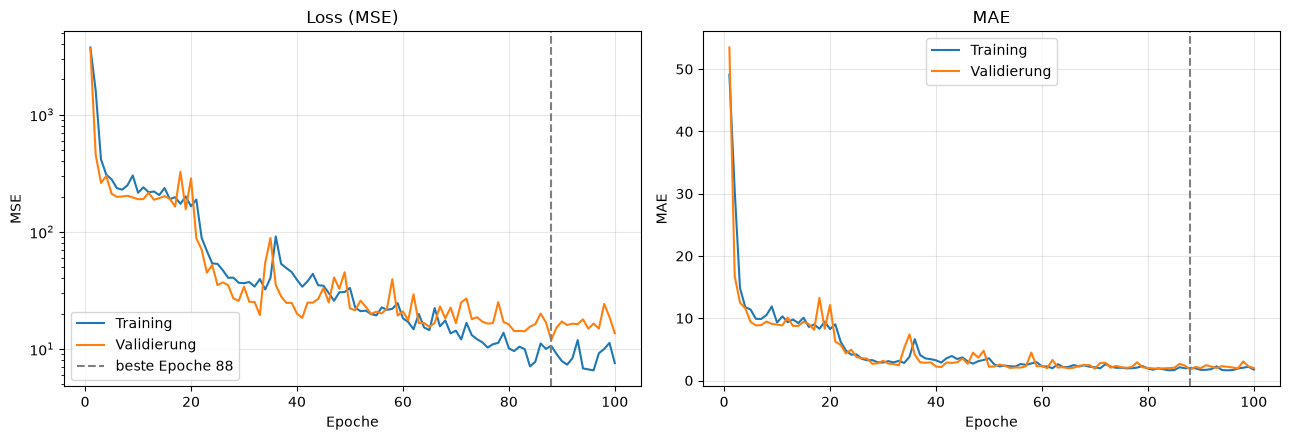

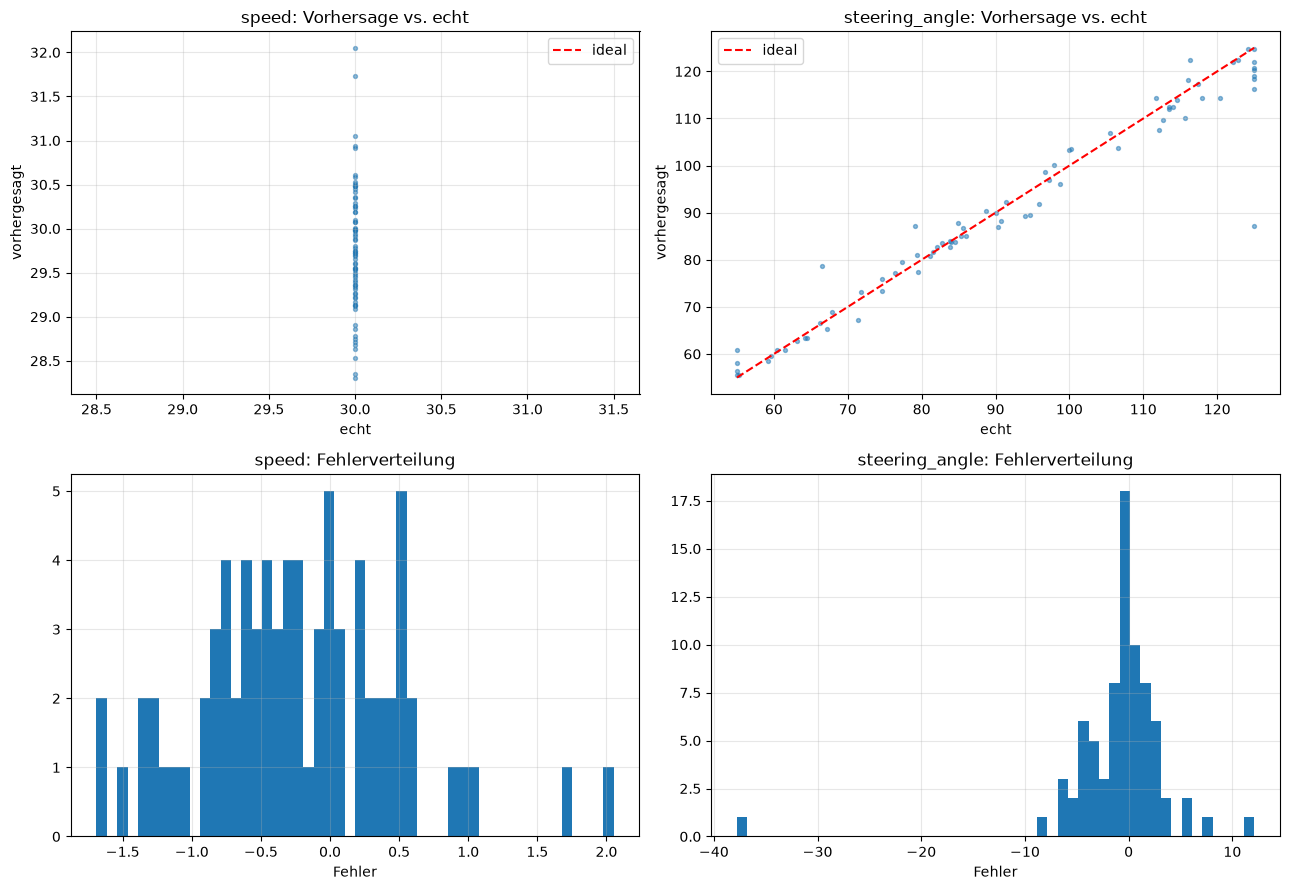

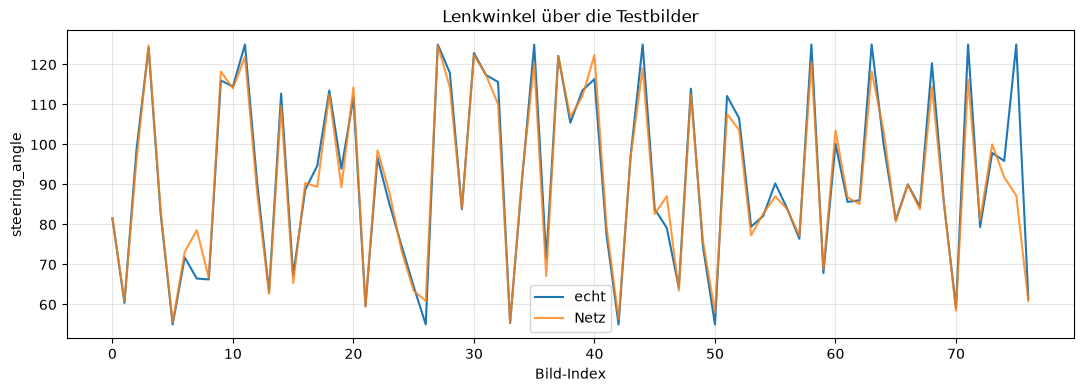

In [9]:
import numpy as np
import matplotlib.pyplot as plt

h = history.history; ep = np.arange(1, len(h['loss']) + 1); best = int(np.argmin(h['val_loss'])) + 1

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(ep, h['loss'], label='Training'); ax[0].plot(ep, h['val_loss'], label='Validierung')
ax[0].axvline(best, color='gray', ls='--', label=f'beste Epoche {best}'); ax[0].set_yscale('log')
ax[0].set(title='Loss (MSE)', xlabel='Epoche', ylabel='MSE'); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].plot(ep, h['mae'], label='Training'); ax[1].plot(ep, h['val_mae'], label='Validierung')
ax[1].axvline(best, color='gray', ls='--'); ax[1].set(title='MAE', xlabel='Epoche', ylabel='MAE'); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()



y_true = np.concatenate([y.numpy() for _, y in test_ds]); y_pred = model.predict(test_ds, verbose=0)
names = ['speed', 'steering_angle']   # Reihenfolge an dein Y anpassen

fig, ax = plt.subplots(2, 2, figsize=(13, 9))
for i, n in enumerate(names):
    lim = [y_true[:, i].min(), y_true[:, i].max()]
    ax[0, i].scatter(y_true[:, i], y_pred[:, i], s=8, alpha=0.5); ax[0, i].plot(lim, lim, 'r--', label='ideal')
    ax[0, i].set(title=f'{n}: Vorhersage vs. echt', xlabel='echt', ylabel='vorhergesagt'); ax[0, i].legend(); ax[0, i].grid(alpha=0.3)
    ax[1, i].hist(y_pred[:, i] - y_true[:, i], bins=50); ax[1, i].set(title=f'{n}: Fehlerverteilung', xlabel='Fehler'); ax[1, i].grid(alpha=0.3)
plt.tight_layout(); plt.show()

plt.figure(figsize=(13, 4)); plt.plot(y_true[:, 1], label='echt'); plt.plot(y_pred[:, 1], label='Netz', alpha=0.8)
plt.title('Lenkwinkel über die Testbilder'); plt.xlabel('Bild-Index'); plt.ylabel('steering_angle'); plt.legend(); plt.grid(alpha=0.3); plt.show()

Schritt 1: Modell speichern und testen (PC, nach model.fit)
- MAE (Mean Absolute Error) - Absolute Fehler des Outputs, da hier nicht skaliert -> etwa 1 bis 2 grad -> OK
- MSE (Mean Squared Error) - Die Einheit ist das Quadrat der Zielwerte, deshalb ist der MSE schwer direkt zu lesen. Besser lesbar ist die Wurzel daraus, der RMSE: (Wurzel(MSE)) 

In [10]:
model.save('deepcar.keras')   # vollständiges Modell: Architektur + Gewichte

test_loss, test_mae = model.evaluate(test_ds)
print(f'Test-MSE: {test_loss:.4f}  Test-MAE: {test_mae:.4f}')

y_true = np.concatenate([y.numpy() for _, y in test_ds]); y_pred = model.predict(test_ds, verbose=0)
y_mean = np.concatenate([y.numpy() for _, y in train_ds]).mean(axis=0)

print('MAE  [speed, steering]:', np.abs(y_pred - y_true).mean(axis=0))
print('Basis-MAE (nur Mittelwert):', np.abs(y_mean - y_true).mean(axis=0))
print('R² [speed, steering]:', 1 - ((y_pred - y_true)**2).mean(axis=0) / y_true.var(axis=0))

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 14.8588 - mae: 1.6822
Test-MSE: 14.8588  Test-MAE: 1.6822
MAE  [speed, steering]: [0.58902484 2.7754264 ]
Basis-MAE (nur Mittelwert): [ 0.       19.101513]
R² [speed, steering]: [      -inf 0.94128376]


Schritt 2: In TFLite umwandeln (PC)

In [11]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]   # Gewichte als int8, Datei ca. 4x kleiner
open('deepcar.tflite', 'wb').write(converter.convert())

INFO:tensorflow:Assets written to: /var/folders/2m/tpb_tvj95t788nbz5qz4v7ww0000gp/T/tmptj19m7hv/assets


INFO:tensorflow:Assets written to: /var/folders/2m/tpb_tvj95t788nbz5qz4v7ww0000gp/T/tmptj19m7hv/assets


Saved artifact at '/var/folders/2m/tpb_tvj95t788nbz5qz4v7ww0000gp/T/tmptj19m7hv'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 240, 320, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  6265081488: TensorSpec(shape=(), dtype=tf.resource, name=None)
  6265081104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  6265083024: TensorSpec(shape=(), dtype=tf.resource, name=None)
  6265082448: TensorSpec(shape=(), dtype=tf.resource, name=None)
  6265082640: TensorSpec(shape=(), dtype=tf.resource, name=None)
  6265080912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  6265082256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  6265083600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  6265083792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  6265083408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  6265080720: TensorSp

W0000 00:00:1793116830.225701 11716690 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1793116830.225831 11716690 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1793116830.227291 11716690 reader.cc:83] Reading SavedModel from: /var/folders/2m/tpb_tvj95t788nbz5qz4v7ww0000gp/T/tmptj19m7hv
I0000 00:00:1793116830.227817 11716690 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1793116830.227819 11716690 reader.cc:147] Reading SavedModel debug info (if present) from: /var/folders/2m/tpb_tvj95t788nbz5qz4v7ww0000gp/T/tmptj19m7hv
I0000 00:00:1793116830.232952 11716690 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
I0000 00:00:1793116830.233882 11716690 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1793116830.270191 11716690 loader.cc:220] Running initialization op on SavedModel bundle at path: /var/folders/2m/tpb_tvj95t788nbz5qz4v7ww0000gp/T/tmptj19m7hv
I0000 00:00:1793116830.278305 11

5008776

Prüfe danach, ob TFLite dasselbe ausgibt wie Keras:

In [12]:
interp = tf.lite.Interpreter(model_path='deepcar.tflite'); interp.allocate_tensors()
inp, out = interp.get_input_details()[0], interp.get_output_details()[0]
x, y = next(iter(test_ds.unbatch().batch(1)))
interp.set_tensor(inp['index'], x.numpy().astype(np.float32)); interp.invoke()
print('Keras :', model.predict(x, verbose=0)[0]); print('TFLite:', interp.get_tensor(out['index'])[0]); print('Soll  :', y.numpy()[0])

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


Keras : [30.256916 81.56613 ]
TFLite: [30.115091 81.98237 ]
Soll  : [30.      81.55727]
